# FTWP Chapter 4 — Review and Exercises

This notebook consolidates the **six non-capstone tasks** for FTWP Chapter 4:
three review exercises and three regular exercises. The problem statements are
paraphrased from the CPF exercise sheet. Numerical parameters are stated where
the source task leaves them open.

The notebook is designed to run from top to bottom in Google Colab or a standard
Python/Jupyter environment.

In [1]:
%matplotlib inline

## Review exercises

### 1. CRRA utility and marginal utility

For $\gamma\ne1$,

$$u(c)=\frac{c^{1-\gamma}}{1-\gamma},\qquad u'(c)=c^{-\gamma}.$$

### 2. Two-date first-order condition

For

$$\max\; u(c_0)+\beta\sum_s p_su(c_{1,s})$$

subject to

$$c_0+\sum_s\psi_sc_{1,s}=w,$$

the FOCs imply

$$\psi_s=\beta p_s\frac{u'(c_{1,s})}{u'(c_0)}.$$

### 3. State-price density

The pricing kernel is $m_s=\psi_s/p_s$. It is high in states where marginal
utility is high, so payoffs delivered in bad consumption states are especially
valuable.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def crra_utility(c, gamma):
    c = np.asarray(c, dtype=float)
    if np.isclose(gamma, 1.0):
        return np.log(c)
    return c ** (1.0 - gamma) / (1.0 - gamma)

def crra_marginal_utility(c, gamma):
    return np.asarray(c, dtype=float) ** (-gamma)

consumption = np.array([0.8, 1.0, 1.2])
gamma_demo = 2.0

utility_table = pd.DataFrame(
    {
        "Consumption": consumption,
        "Utility": crra_utility(consumption, gamma_demo),
        "Marginal utility": crra_marginal_utility(consumption, gamma_demo),
    }
)
display(utility_table)

,Consumption,Utility,Marginal utility
0,0.8,-1.250000,1.562500
1,1.0,-1.000000,1.000000
2,1.2,-0.833333,0.694444


## Regular exercises

### 4. Representative-agent pricing kernel and asset prices

Use $\beta=0.95$, $P=(0.5,0.5)$, consumption growth $g=(1.2,0.8)$, and
baseline risk aversion $\gamma=2$. The CRRA pricing kernel is

$$m_s=\beta g_s^{-\gamma}.$$

### 5. Effect of changing risk aversion

Compare $\gamma=1$ and $\gamma=4$ while holding the endowment process fixed.

### 6. Numerical Euler-equation verification

For every gross return $R$, equilibrium requires $E[mR]=1$.

Baseline pricing kernel: [0.65972222 1.484375  ]
Baseline state prices: [0.32986111 0.7421875 ]
Baseline risk-free rate: -0.06720647773279353
Baseline risky asset price: 1.0555555555555554
Bond Euler equation: 0.9999999999999999
Risky Euler equation: 1.0


,Gamma,m_up,m_down,Down/Up kernel ratio,Risk-free rate,Risky price,Expected risky return,Premium
World,,,,,,,,
Low risk aversion,1.0,0.791667,1.187500,1.5000,0.010526,1.029167,0.068826,0.058300
High risk aversion,4.0,0.458140,2.319336,5.0625,-0.279922,1.248433,-0.118895,0.161027


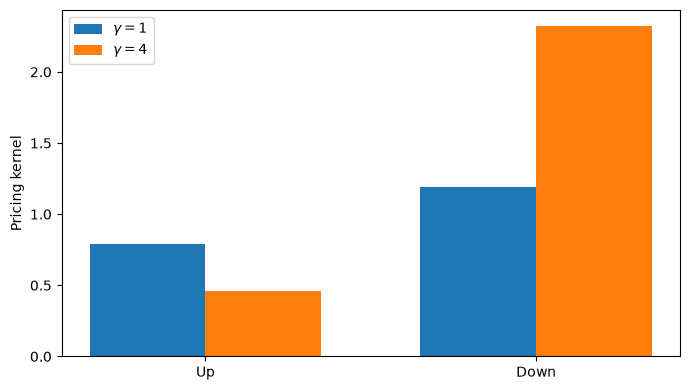

In [3]:
beta = 0.95
P = np.array([0.5, 0.5])
growth = np.array([1.2, 0.8])
risky_payoff = np.array([1.4, 0.8])

def equilibrium(gamma):
    m = beta * growth ** (-gamma)
    state_prices = P * m
    bond_price = state_prices.sum()
    Rf = 1.0 / bond_price
    risky_price = state_prices @ risky_payoff
    risky_returns = risky_payoff / risky_price
    expected_risky_return = P @ risky_returns
    return {
        "gamma": gamma,
        "m": m,
        "state_prices": state_prices,
        "bond_price": bond_price,
        "Rf": Rf,
        "rf": Rf - 1.0,
        "risky_price": risky_price,
        "risky_returns": risky_returns,
        "expected_risky_return": expected_risky_return,
        "premium": expected_risky_return - Rf,
        "euler_bond": P @ (m * Rf),
        "euler_risky": P @ (m * risky_returns),
    }

baseline = equilibrium(2.0)
low = equilibrium(1.0)
high = equilibrium(4.0)

comparison = pd.DataFrame(
    [
        {
            "World": "Low risk aversion",
            "Gamma": low["gamma"],
            "m_up": low["m"][0],
            "m_down": low["m"][1],
            "Down/Up kernel ratio": low["m"][1] / low["m"][0],
            "Risk-free rate": low["rf"],
            "Risky price": low["risky_price"],
            "Expected risky return": low["expected_risky_return"] - 1.0,
            "Premium": low["premium"],
        },
        {
            "World": "High risk aversion",
            "Gamma": high["gamma"],
            "m_up": high["m"][0],
            "m_down": high["m"][1],
            "Down/Up kernel ratio": high["m"][1] / high["m"][0],
            "Risk-free rate": high["rf"],
            "Risky price": high["risky_price"],
            "Expected risky return": high["expected_risky_return"] - 1.0,
            "Premium": high["premium"],
        },
    ]
).set_index("World")

print("Baseline pricing kernel:", baseline["m"])
print("Baseline state prices:", baseline["state_prices"])
print("Baseline risk-free rate:", baseline["rf"])
print("Baseline risky asset price:", baseline["risky_price"])
print("Bond Euler equation:", baseline["euler_bond"])
print("Risky Euler equation:", baseline["euler_risky"])
display(comparison)

plt.figure(figsize=(7, 4))
x = np.arange(2)
width = 0.35
plt.bar(x - width / 2, low["m"], width, label=r"$\gamma=1$")
plt.bar(x + width / 2, high["m"], width, label=r"$\gamma=4$")
plt.xticks(x, ["Up", "Down"])
plt.ylabel("Pricing kernel")
plt.legend()
plt.tight_layout()
plt.show()

Higher risk aversion puts much greater relative weight on the low-consumption
Down state. This changes both safe and risky prices. The comparison is a
stylized equilibrium experiment; it is not an empirical estimate of investor
risk aversion or market interest rates.

In [4]:
checks = {
    "marginal utility formula": np.allclose(crra_marginal_utility(consumption, 2.0), consumption ** -2.0),
    "probabilities": np.isclose(P.sum(), 1.0),
    "positive kernel": np.all(baseline["m"] > 0),
    "state prices": np.allclose(baseline["state_prices"], P * baseline["m"]),
    "bond Euler equation": np.isclose(baseline["euler_bond"], 1.0),
    "risky Euler equation": np.isclose(baseline["euler_risky"], 1.0),
    "higher bad-state relative weight": high["m"][1] / high["m"][0] > low["m"][1] / low["m"][0],
}

for name, passed in checks.items():
    print(f"{name}: {passed}")
assert all(checks.values())

marginal utility formula: True
probabilities: True
positive kernel: True
state prices: True
bond Euler equation: True
risky Euler equation: True
higher bad-state relative weight: True
